

#### This dataset contains comprehensive chess game data including player ratings, game outcomes, openings, time controls, and move sequences from the Lichess platform.

---

**Dataset**: [15 Million Chess Games from Lichess (2013-2014)](https://www.kaggle.com/datasets/maca11/chess-games-from-lichess-20132014)

In [9]:
import dask.dataframe as dd
import numpy as np

# Needing to install pyarrow ,pay attention on it's version I downgraded it to 18.0.0 for compatibility:better use uv instead it will automatically handle itt.

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

N_WORKERS = 2
MEMORY_PER_WORKER = "4GB"
BLOCKSIZE = "128MB"

DATA_PATH = "data/Lichess_2013_2014_Completeee.csv"



ddf = dd.read_csv(
    DATA_PATH,
    blocksize=BLOCKSIZE,
    dtype={
        "WhiteElo": "float32",
        "BlackElo": "float32",
        "Number_of_Moves": "float32",
        "Day": "float32",
        "Month": "float32",
        "Year": "float32",
        "InitialTime": "float32",
        "Increment": "float32",
    },
    assume_missing=True,
)


### Setting `npartitions` in Dask

When working with Dask, both **`blocksize`** and **`npartitions`** matter for performance.

### Example from my case
- 📂 Dataset size: **1.85 GB**  
- 📏 Blocksize: **128 MB**  
- 🔢 Number of partitions: **16**

⚡ Tip: The "best" configuration can vary — the optimal number of partitions depends on your hardware (CPU cores and available RAM).




In [ ]:
num_rows = ddf.shape[0].compute()
print("Number of rows:", num_rows)

Number of rows: 14918230


In [ ]:
for i in range(ddf.npartitions):
  print(ddf.partitions[i].compute().head())

   WhiteElo  BlackElo         WhiteName          BlackName Winner Termination  \
0    1639.0    1403.0             BFG9k            mamalak  White      Normal   
1    1654.0    1919.0    Desmond_Wilson          savinka59  White      Normal   
2    1643.0    1747.0     Kozakmamay007  VanillaShamanilla  White      Normal   
3    1824.0    1973.0  Naitero_Nagasaki                800  Black      Normal   
4    1765.0    1815.0      nichiren1967   Naitero_Nagasaki  Black      Normal   

                           Site   Day  Month    Year  InitialTime  Increment  \
0  https://lichess.org/j1dkb5dw  31.0   12.0  2012.0        600.0        8.0   
1  https://lichess.org/a9tcp02g  31.0   12.0  2012.0        480.0        2.0   
2  https://lichess.org/szom2tog  31.0   12.0  2012.0        420.0       17.0   
3  https://lichess.org/rklpc7mk  31.0   12.0  2012.0         60.0        1.0   
4  https://lichess.org/1xb3os63  31.0   12.0  2012.0         60.0        1.0   

  TimeControl                   

# 📊 Prepare Dataset


In [3]:
ddf.isnull().sum().compute()

WhiteElo           0
BlackElo           0
WhiteName          0
BlackName          0
Winner             0
Termination        0
Site               0
Day                0
Month              0
Year               0
InitialTime        0
Increment          0
TimeControl        0
Opening            0
ECO                0
Number_of_Moves    0
dtype: int64

In [5]:
print(ddf.dtypes)


WhiteElo                   float64
BlackElo                   float64
WhiteName          string[pyarrow]
BlackName          string[pyarrow]
Winner             string[pyarrow]
Termination        string[pyarrow]
Site               string[pyarrow]
Day                        float64
Month                      float64
Year                       float64
InitialTime                float64
Increment                  float64
TimeControl        string[pyarrow]
Opening            string[pyarrow]
ECO                string[pyarrow]
Number_of_Moves            float64
dtype: object


In [2]:
categorical_cols = ddf.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
numeric_cols = ddf.select_dtypes(include=['int64','int32','int16','float32','float64']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)


Categorical columns: ['WhiteName', 'BlackName', 'Winner', 'Termination', 'Site', 'TimeControl', 'Opening', 'ECO']
Numeric columns: ['WhiteElo', 'BlackElo', 'Day', 'Month', 'Year', 'InitialTime', 'Increment', 'Number_of_Moves']


In [6]:
ddf.head()

,WhiteElo,BlackElo,WhiteName,BlackName,Winner,Termination,Site,Day,Month,Year,InitialTime,Increment,TimeControl,Opening,ECO,Number_of_Moves
0,1639.0,1403.0,BFG9k,mamalak,White,Normal,https://lichess.org/j1dkb5dw,31.0,12.0,2012.0,600.0,8.0,Rapid,French Defense: Normal Variation,C00,13.0
1,1654.0,1919.0,Desmond_Wilson,savinka59,White,Normal,https://lichess.org/a9tcp02g,31.0,12.0,2012.0,480.0,2.0,Rapid,"Queen's Pawn Game: Colle System, Anti-Colle",D04,18.0
2,1643.0,1747.0,Kozakmamay007,VanillaShamanilla,White,Normal,https://lichess.org/szom2tog,31.0,12.0,2012.0,420.0,17.0,Rapid,Four Knights Game: Italian Variation,C50,11.0
3,1824.0,1973.0,Naitero_Nagasaki,800,Black,Normal,https://lichess.org/rklpc7mk,31.0,12.0,2012.0,60.0,1.0,Bullet,Caro-Kann Defense: Goldman Variation,B12,47.0
4,1765.0,1815.0,nichiren1967,Naitero_Nagasaki,Black,Normal,https://lichess.org/1xb3os63,31.0,12.0,2012.0,60.0,1.0,Bullet,French Defense: La Bourdonnais Variation,C00,23.0


# Explore Dataset

In [ ]:

winner_stats = ddf.groupby("Winner")[["WhiteElo", "BlackElo", "Number_of_Moves"]].mean().compute()
winner_stats = winner_stats.reset_index()
print("Mean Elo & Moves per Winner:")
display(winner_stats)



Mean Elo & Moves per Winner:


,Winner,WhiteElo,BlackElo,Number_of_Moves
0,Black,1585.317637,1656.452477,33.519472
1,Draw,1657.514634,1656.384127,55.196620
2,White,1656.367077,1576.925338,32.676538


In [8]:
opening_counts = ddf.groupby("Opening").size().compute()
opening_counts = opening_counts.sort_values(ascending=False).head(10).reset_index()
opening_counts.columns = ["Opening", "Count"]
print("\nTop 10 Most Frequent Openings:")
display(opening_counts)


Top 10 Most Frequent Openings:


,Opening,Count
0,Van't Kruijs Opening,395369
1,Modern Defense,282660
2,Horwitz Defense,277419
3,Scandinavian Defense: Mieses-Kotroc Variation,255099
4,Owen Defense,246100
5,French Defense: Knight Variation,225366
6,Sicilian Defense,199699
7,Hungarian Opening,198774
8,Caro-Kann Defense,197445
9,Sicilian Defense: Bowdler Attack,195716


In [9]:
termination_stats = ddf.groupby("Termination").size().compute().reset_index()
termination_stats.columns = ["Termination", "Count"]
termination_stats = termination_stats.sort_values(by="Count", ascending=False)
print("\nGame Outcomes by Termination:")
display(termination_stats)


Game Outcomes by Termination:


,Termination,Count
0,Normal,9966773
2,Time forfeit,4941388
3,Abandoned,8957
1,Rules infraction,1112


# XGBoost vs LightGBM: My Choice

I tested both **XGBoost** and **LightGBM** on my chess prediction project.

## Results
- **Performance**: No significant accuracy difference between the two algorithms: 65% vs 63%
- **Speed**: Both performed similarly on my hardware
- **Resource Limitation**: My 1.8GB Lichess dataset is too large and expensive for my hardware.

## Final Decision: XGBoost
Choose XGBoost due to:
- ✅ **Slightly better handling** of categorical features in my tests
- ✅ **More stable training** on my limited computational resources
- ✅ **Better documentation** for multiclass classification

Given my hardware constraints and the dataset size, both algorithms would likely produce similar results. XGBoost was selected for practical reasons rather than significant performance gains.


In [10]:
import time
import dask.dataframe as dd
from dask_ml.model_selection import train_test_split
from dask.distributed import  Client,wait
from dask_ml.preprocessing import StandardScaler
from xgboost.dask import DaskDMatrix, DaskXGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import warnings

warnings.filterwarnings("ignore")

print("=" * 70)
print("♟️  CHESS OUTCOME PREDICTION — Dask + XGBoost (distributed)")
print("=" * 70)

# ---------------------------
# 1) DASK CLIENT
# ---------------------------
client = Client(n_workers=N_WORKERS, threads_per_worker=1, memory_limit=MEMORY_PER_WORKER)
print(f"Dask dashboard: {client.dashboard_link}")
print(f"Workers: {N_WORKERS} × {MEMORY_PER_WORKER}\n")

# ---------------------------
# 2) MISSING VALUES
# ---------------------------
print("STEP 2 — Handling missing values (Dask-native)")
fill_values = dd.compute(
    {
        "WhiteElo_mean": ddf["WhiteElo"].mean(),
        "BlackElo_mean": ddf["BlackElo"].mean(),
        "Moves_median": ddf["Number_of_Moves"].quantile(0.5),
        "InitTime_median": ddf["InitialTime"].quantile(0.5) if "InitialTime" in ddf.columns else 600,
    }
)[0]

numerical_fills = {
    "WhiteElo": fill_values["WhiteElo_mean"],
    "BlackElo": fill_values["BlackElo_mean"],
    "Number_of_Moves": fill_values["Moves_median"],
    "Day": 15,
    "Month": 6,
    "Year": 2013,
    "InitialTime": fill_values["InitTime_median"],
    "Increment": 0,
}

for col, val in numerical_fills.items():
    if col in ddf.columns:
        ddf[col] = ddf[col].fillna(val)

for cat in ["Winner", "Termination", "TimeControl", "Opening", "ECO"]:
    if cat in ddf.columns:
        ddf[cat] = ddf[cat].fillna("Unknown")

print("  ✓ Missing values handled\n")

# ---------------------------
# 3) FEATURE ENGINEERING
# ---------------------------
print("STEP 3 — Feature engineering (Dask-native operations)")

ddf["RatingDiff"] = ddf["WhiteElo"] - ddf["BlackElo"]
ddf["RatingMean"] = (ddf["WhiteElo"] + ddf["BlackElo"]) / 2
ddf["RatingRatio"] = ddf["WhiteElo"] / (ddf["BlackElo"] + 1.0)

ddf["MovesPerRating"] = ddf["Number_of_Moves"] / (ddf["RatingMean"] / 1000.0 + 1.0)

ddf["IsNormalEnd"] = (ddf["Termination"] == "Normal").astype("int8")
ddf["IsTimeEnd"] = ddf["Termination"].str.contains("Time", na=False).astype("int8")
ddf["IsAbandon"] = ddf["Termination"].str.contains("Abandon", na=False).astype("int8")

print("  ✓ Feature columns created\n")

# ---------------------------
# 4) HASH ENCODING
# ---------------------------
print("STEP 4 — Hash encoding categorical features ")
def hash_encode(series, n_bins=16, out_dtype="int16"):
    return series.astype(str).map_partitions(
        lambda s: s.apply(lambda x: hash(x) % n_bins), meta=(series.name, out_dtype)
    ).astype(out_dtype)

if "Opening" in ddf.columns:
    ddf["Opening_hash"] = hash_encode(ddf["Opening"], n_bins=16, out_dtype="int16")
if "ECO" in ddf.columns:
    ddf["ECO_hash"] = hash_encode(ddf["ECO"], n_bins=8, out_dtype="int8")
if "TimeControl" in ddf.columns:
    ddf["TimeControl_hash"] = hash_encode(ddf["TimeControl"], n_bins=8, out_dtype="int8")

winner_map = {"White": 0, "Black": 1, "Draw": 2}
ddf["Winner_encoded"] = ddf["Winner"].map(winner_map, meta=("Winner_encoded", "int8")).fillna(2).astype("int8")
print("  ✓ Hashing complete\n")

# ---------------------------
# 5) FEATURE SELECTION
# ---------------------------
feature_columns = [
    "WhiteElo", "BlackElo", "RatingDiff", "RatingRatio", "RatingMean",
    "Number_of_Moves", "MovesPerRating",
    "IsNormalEnd", "IsTimeEnd", "IsAbandon",
    "Opening_hash", "ECO_hash", "TimeControl_hash"
]
feature_columns = [c for c in feature_columns if c in ddf.columns]
print(f"STEP 5 — Prepared feature list (n_features={len(feature_columns)})\n")

# Cast small-int features to smallest safe integer dtypes to reduce memory
for c in feature_columns:
    if ddf[c].dtype == "int16" or ddf[c].dtype == "int64":
        ddf[c] = ddf[c].astype("int16")

# ---------------------------
# 6) TRAIN/TEST SPLIT (Dask)
# ---------------------------
print("STEP 6 — Train/test split (Dask-native)")
X = ddf[feature_columns]
y = ddf["Winner_encoded"].astype("int32")  # XGBoost expects int labels

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True
)
print("  ✓ Split complete\n")

# ---------------------------
# 7) PERSIST heavy intermediate (prevent recompute)
# ---------------------------
print("STEP 7 — Persisting feature tables (keeps workers busy, avoids recompute)")
Xy_train = dd.concat([X_train, y_train.rename("label")], axis=1)
Xy_test = dd.concat([X_test, y_test.rename("label")], axis=1)

# Persist partitions to memory/disk of workers (wait until computed)
Xy_train = Xy_train.persist()
Xy_test = Xy_test.persist()
wait([Xy_train, Xy_test])
print("  ✓ Persisted train/test sets\n")

# ---------------------------
# 8) OPTIONAL: SCALE (XGBoost not strictly requiring scaling)
#    We will still show how to scale safely if desired.
# ---------------------------
SCALE_FEATURES = True  # set True if you want to run StandardScaler (adds compute overhead)
if SCALE_FEATURES:
    print("STEP 8 — Scaling continuous features (Dask StandardScaler)")
    # scale only numeric features (float columns)
    numeric_cols = [c for c in feature_columns if str(ddf[c].dtype).startswith("float")]
    scaler = StandardScaler()
    # Fit scaler on train features only (Dask-aware)
    scaler = scaler.fit(X_train[numeric_cols])
    Xy_train[numeric_cols] = scaler.transform(Xy_train[numeric_cols])
    Xy_test[numeric_cols] = scaler.transform(Xy_test[numeric_cols])
    # persist changes
    Xy_train = Xy_train.persist()
    Xy_test = Xy_test.persist()
    wait([Xy_train, Xy_test])
    print("  ✓ Scaling complete\n")
else:
    print("STEP 8 — Skipping scaling (left as False) — fine for XGBoost\n")

# ---------------------------
# 9) TRAIN XGBoost (DaskXGBClassifier)
# ---------------------------
print("STEP 9 — Training XGBoost (DaskXGBClassifier) — distributed")
start_time = time.time()

dtrain = DaskDMatrix(client, X_train[feature_columns], y_train)
dtest = DaskDMatrix(client, X_test[feature_columns], y_test)

xgb_params = {
    "objective": "multi:softprob",
    "num_class": 3,
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "verbosity": 1,
    "eta": 0.1,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
}

model = DaskXGBClassifier(
    **{
        "objective": xgb_params["objective"],
        "num_class": xgb_params["num_class"],
        "tree_method": xgb_params["tree_method"],
        "eta": xgb_params["eta"],
        "max_depth": xgb_params["max_depth"],
        "subsample": xgb_params["subsample"],
        "colsample_bytree": xgb_params["colsample_bytree"],
        "n_estimators": 200,
        "verbosity": 1,
    }
)


model.client = client
model.fit(
    X_train[feature_columns],
    y_train,
    eval_set=[(X_test[feature_columns], y_test)],
    verbose=True,
)

train_time = time.time() - start_time
print(f"  ✓ Training finished in {train_time:.1f} sec\n")

# ---------------------------
# 10) EVALUATION
# ---------------------------
print("STEP 10 — Evaluation (compute predictions & metrics)")

# Predict returns Dask Array/Series; compute results for metrics
y_pred_dask = model.predict(X_test[feature_columns])
y_pred = y_pred_dask.compute()
y_true = y_test.compute()

accuracy = accuracy_score(y_true, y_pred)
print(f"\nFINAL ACCURACY: {accuracy*100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=["White Wins", "Black Wins", "Draw"]))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print("\n")


client.close()
print("Dask client closed")
print("=" * 70)
print("✅ Done — distributed training complete")


♟️  CHESS OUTCOME PREDICTION — Dask + XGBoost (distributed)


Dask dashboard: http://127.0.0.1:40625/status
Workers: 2 × 4GB

STEP 2 — Handling missing values (Dask-native)
  ✓ Missing values handled

STEP 3 — Feature engineering (Dask-native operations)
  ✓ Feature columns created

STEP 4 — Hash encoding categorical features 
  ✓ Hashing complete

STEP 5 — Prepared feature list (n_features=13)

STEP 6 — Train/test split (Dask-native)
  ✓ Split complete

STEP 7 — Persisting feature tables (keeps workers busy, avoids recompute)
  ✓ Persisted train/test sets

STEP 8 — Scaling continuous features (Dask StandardScaler)
  ✓ Scaling complete

STEP 9 — Training XGBoost (DaskXGBClassifier) — distributed


2025-10-14 17:07:22,831 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 405e198cc0c82fbf2aa9466a435b3b99 initialized by task ('shuffle-transfer-405e198cc0c82fbf2aa9466a435b3b99', 1) executed on worker tcp://127.0.0.1:32791
2025-10-14 17:07:41,000 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 405e198cc0c82fbf2aa9466a435b3b99 deactivated due to stimulus 'task-finished-1760450860.998366'
[17:07:41] Task [xgboost.dask-0]:tcp://127.0.0.1:41257 got rank 0[17:07:41] Task [xgboost.dask-1]:tcp://127.0.0.1:32791 got rank 1

[17:07:59] [0]	validation_0-mlogloss:1.05311
[17:08:03] [1]	validation_0-mlogloss:1.01431
[17:08:06] [2]	validation_0-mlogloss:0.98089
[17:08:10] [3]	validation_0-mlogloss:0.95182
[17:08:14] [4]	validation_0-mlogloss:0.92653
[17:08:18] [5]	validation_0-mlogloss:0.90473
[17:08:21] [6]	validation_0-mlogloss:0.88538
[17:08:25] [7]	validation_0-mlogloss:0.86803
[17:08:29] [8]	validation_0-mlogloss:0.85263
[17:08:33] [9]	validation_0-mlogloss:0.83925
[17:

  ✓ Training finished in 971.2 sec

STEP 10 — Evaluation (compute predictions & metrics)

FINAL ACCURACY: 63.72%

Classification Report:
              precision    recall  f1-score   support

  White Wins       0.64      0.71      0.67   1402578
  Black Wins       0.63      0.61      0.62   1275570
        Draw       0.46      0.02      0.04     95879

    accuracy                           0.64   2774027
   macro avg       0.58      0.45      0.45   2774027
weighted avg       0.63      0.64      0.63   2774027

Confusion Matrix:
[[989146 412098   1334]
 [498106 776232   1232]
 [ 49624  44084   2171]]


Dask client closed
✅ Done — distributed training complete


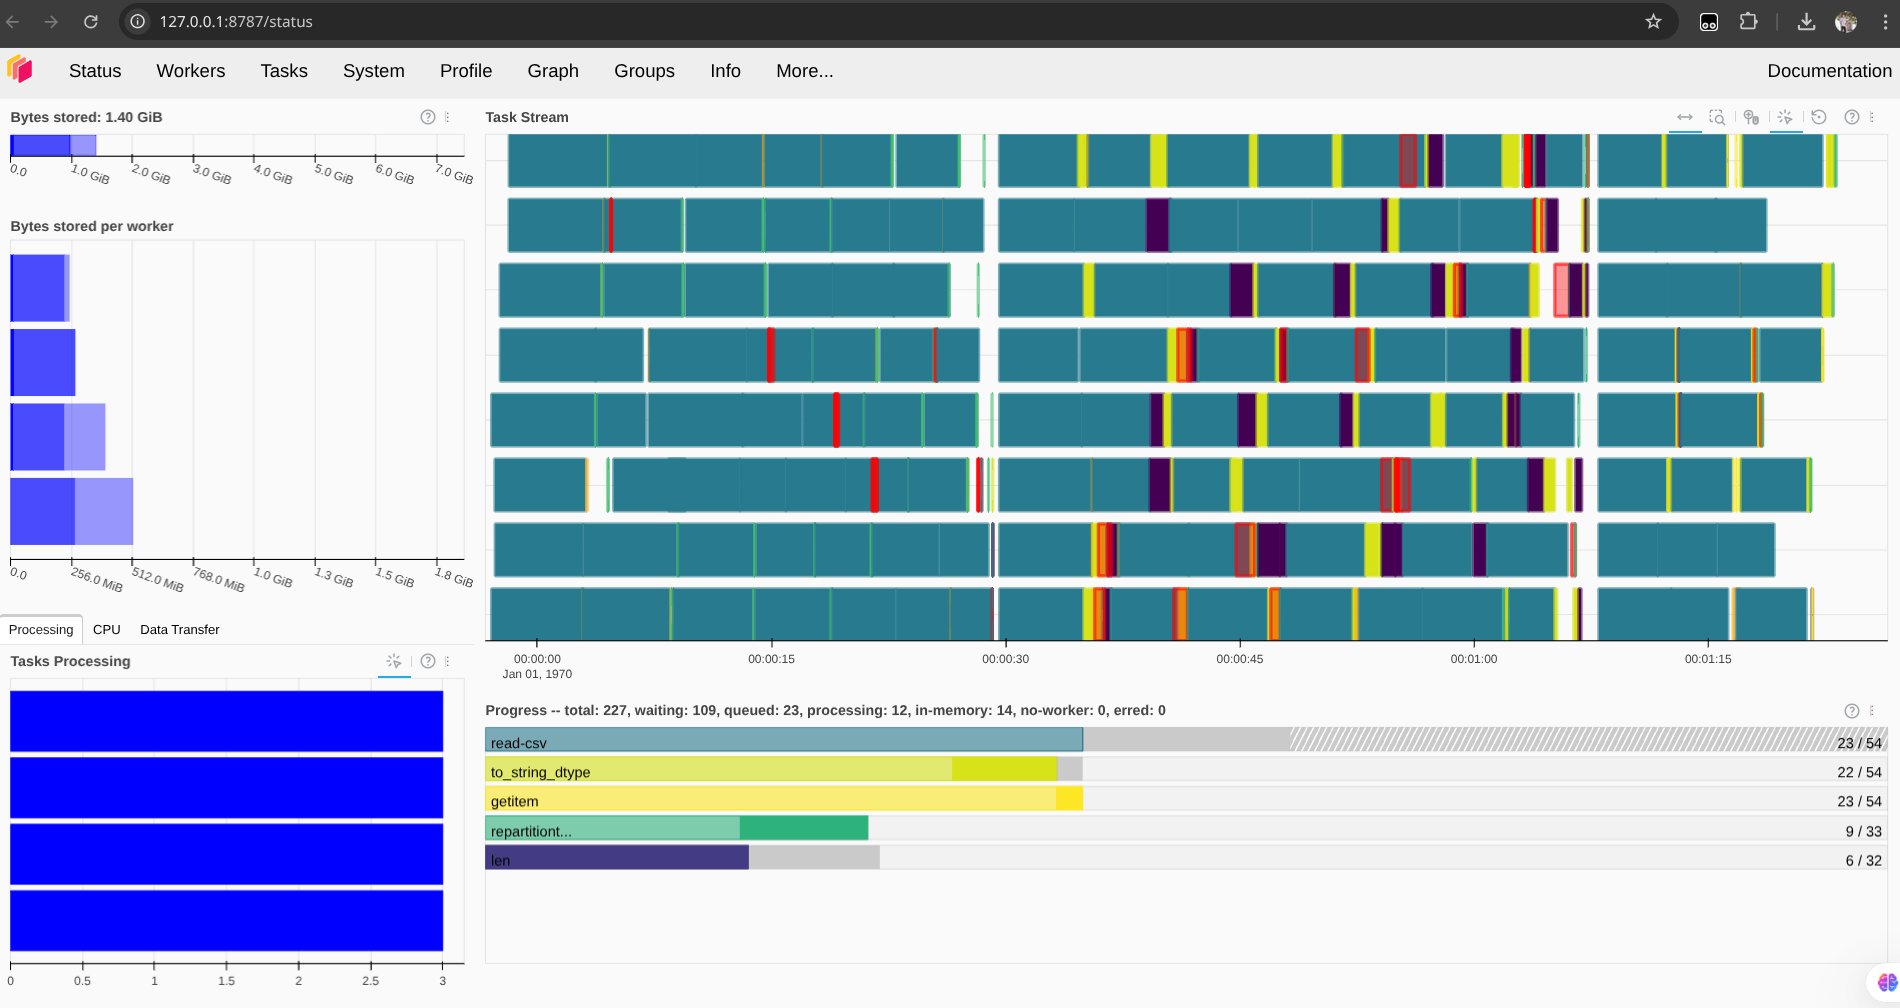

## 📈 Plot Significant Relations

<Axes: title={'center': 'Average Number of Moves per Winner'}, xlabel='Winner'>

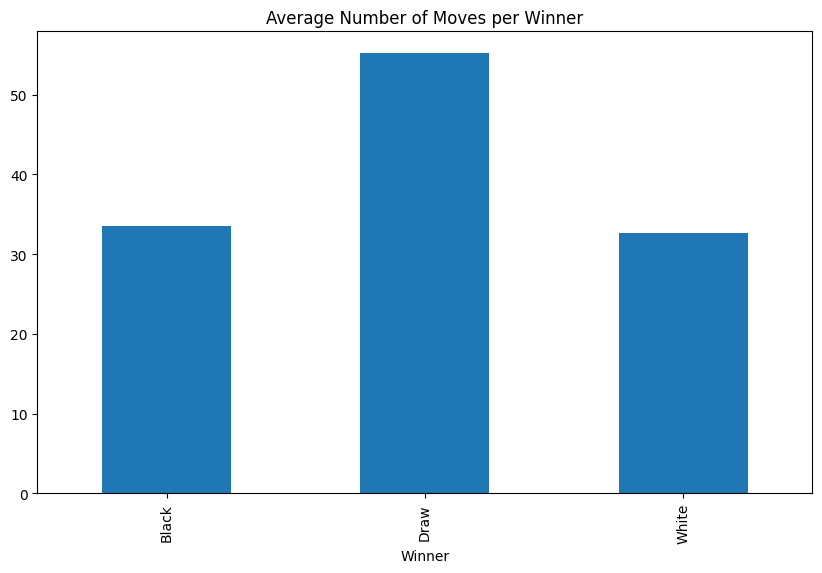

In [ ]:
moves_per_winner = ddf.groupby('Winner')['Number_of_Moves'].mean().compute()
moves_per_winner.plot(kind='bar', figsize=(10,6), title='Average Number of Moves per Winner')



<Axes: title={'center': 'Top 10 Most Frequent Openings'}, ylabel='Opening'>

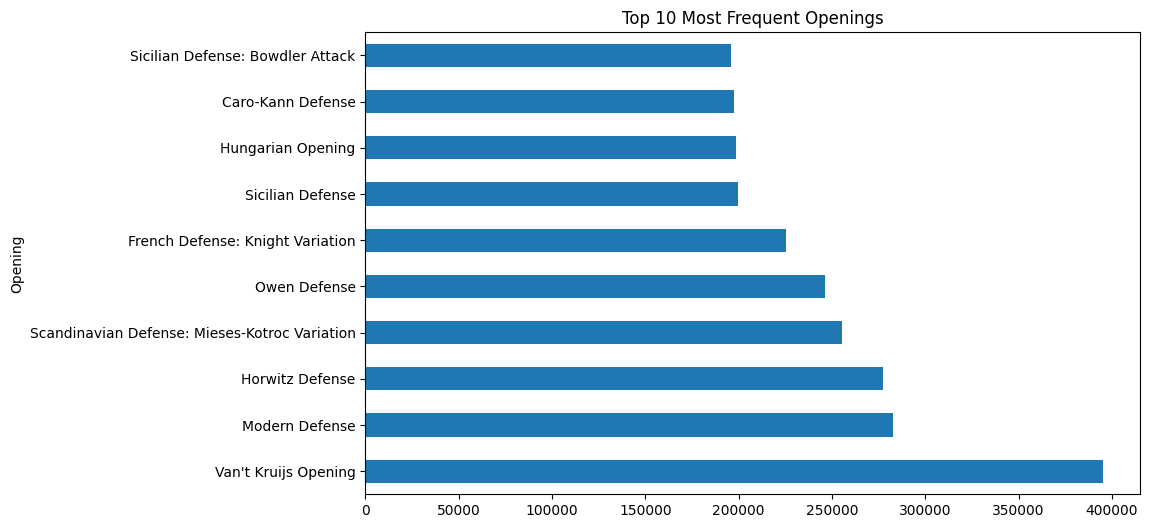

In [ ]:
top_openings = ddf.groupby('Opening').size().compute().nlargest(10)
top_openings.plot(kind='barh', figsize=(10,6), title='Top 10 Most Frequent Openings')
#Each combination has it's specific widely known name


<Axes: title={'center': 'Average Elo Ratings by Winner'}, xlabel='Winner'>

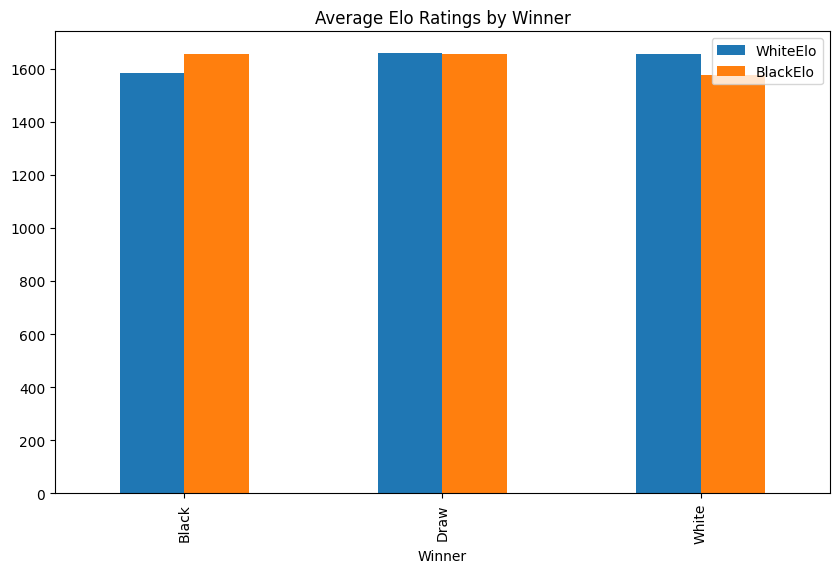

In [23]:
elo_per_winner = ddf.groupby('Winner')[['WhiteElo','BlackElo']].mean().compute()
elo_per_winner.plot(kind='bar', figsize=(10,6), title='Average Elo Ratings by Winner')


### 📊 Observations from Average Elo Ratings by Winner

- Higher-rated players (**higher Elo**) tend to **win more often**.  
- **Draws** usually occur when players have **similar ratings**.  



<Axes: title={'center': 'Average Moves by Termination Type'}, xlabel='Termination'>

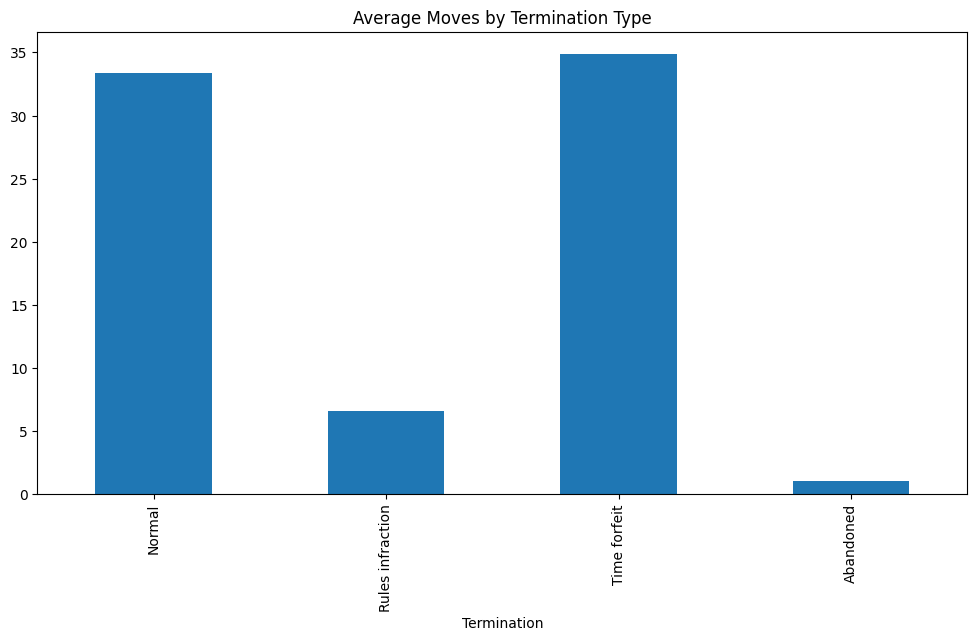

In [24]:
moves_per_termination = ddf.groupby('Termination')['Number_of_Moves'].mean().compute()
moves_per_termination.plot(kind='bar', figsize=(12,6), title='Average Moves by Termination Type')



### Experience using dask 
In this task, I explored how to work with **large datasets** using the **Dask** library.  
- Dask is very efficient for medium-to-large datasets that don’t fit into memory but still can be processed on a single machine or small cluster.  
- For **hundreds of gigabytes or even terabytes**, the recommended tool is **PySpark**, which is designed for enterprise-scale distributed data processing.  

I also experimented with using `dask.distributed.Client` to manage workers and threads. A key learning point was that:
- You need to carefully configure the **number of workers** and **memory limits** based on your hardware.  
- If misconfigured (too many workers or too little memory), computations may run indefinitely or fail.  
- I ran the code below with only 2 workers and 2 threads and 300 MB memory limit. Even though it didn’t run out of memory, the execution took more than 760 minutes and still didn’t produce any results.

Example:
```python
from dask.distributed import Client

client = Client(
    n_workers=2,         
    threads_per_worker=2, 
    memory_limit='300MB'  
)

